In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,roc_auc_score,roc_curve,auc


In [2]:
data = pd.read_csv("health_diagnosis_dataset.csv")

In [3]:
data

,Age,Gender,BMI,BloodPressure,Glucose,Insulin,SkinThickness,HeartRate,Cholesterol,PhysicalActivity,Smoking,Alcohol,FamilyHistory,GeneticRiskScore,Diagnosis
0,52,0,21.4,90,78,107,11,75,239,4.6,0,1,0,0.26,0
1,42,0,19.4,128,120,65,9,66,149,0.3,1,0,0,0.51,0
2,54,1,28.9,103,127,94,30,50,245,5.1,1,1,0,0.09,1
3,67,1,27.9,122,71,77,28,55,170,3.9,0,1,0,0.00,0
4,41,1,31.7,92,88,50,14,89,197,2.8,0,0,0,0.86,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,31,1,23.3,108,121,101,8,70,165,0.3,1,1,1,0.44,1
14996,63,1,20.6,105,96,34,10,71,217,7.2,0,0,0,0.37,0
14997,64,1,31.6,140,110,47,32,76,125,4.8,0,0,0,0.36,1
14998,31,0,30.7,114,84,63,22,63,253,1.8,0,1,0,0.28,0


In [4]:
data.shape

(15000, 15)

In [5]:
data.columns

Index(['Age', 'Gender', 'BMI', 'BloodPressure', 'Glucose', 'Insulin',
       'SkinThickness', 'HeartRate', 'Cholesterol', 'PhysicalActivity',
       'Smoking', 'Alcohol', 'FamilyHistory', 'GeneticRiskScore', 'Diagnosis'],
      dtype='str')

In [6]:
data.isnull().sum()

Age                 0
Gender              0
BMI                 0
BloodPressure       0
Glucose             0
Insulin             0
SkinThickness       0
HeartRate           0
Cholesterol         0
PhysicalActivity    0
Smoking             0
Alcohol             0
FamilyHistory       0
GeneticRiskScore    0
Diagnosis           0
dtype: int64

In [7]:
data.describe().T[["mean","std","min","50%","max"]]

,mean,std,min,50%,max
Age,44.773933,14.481676,18.0,45.0,90.0
Gender,0.550067,0.497504,0.0,1.0,1.0
BMI,26.978767,4.979825,15.0,27.0,45.6
BloodPressure,119.909200,17.203597,90.0,120.0,187.0
Glucose,105.572933,28.229983,60.0,105.0,211.0
Insulin,89.888133,34.918598,10.0,90.0,221.0
SkinThickness,19.760800,9.359684,5.0,19.0,58.0
HeartRate,74.702333,11.758084,50.0,75.0,120.0
Cholesterol,199.764133,39.082612,120.0,199.0,344.0
PhysicalActivity,3.051613,1.888126,0.0,3.0,10.0


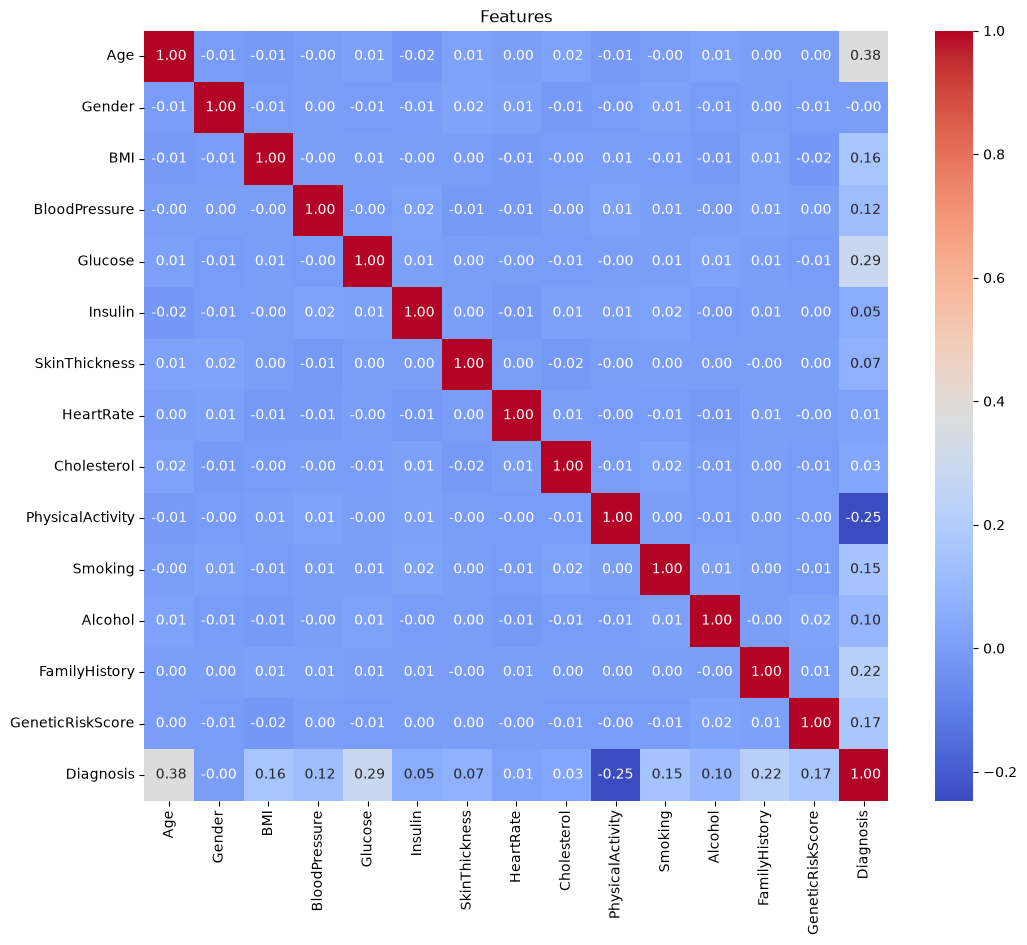

In [8]:
plt.figure(figsize = (12,10))
sns.heatmap(data.corr(),annot = True, cmap = "coolwarm", fmt = " .2f")
plt.title("Features")
plt.show()

In [9]:
X = data.drop(columns = "Diagnosis")
X = pd.DataFrame(X)
Y = data["Diagnosis"]

In [10]:
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42,stratify= Y)

In [11]:
model = Pipeline([("scaler",StandardScaler()),
                  ("clf",LogisticRegression(max_iter=2000))])

In [12]:
model.fit(X_train,Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['Age','Gender','BMI',...,'Alcohol','FamilyHistory','GeneticRiskScore']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [24]:
Y_pred_train = model.predict(X_train)
Y_pred_test = model.predict(X_test)

In [ ]:
print("=== CLASSIFICATION REPORT - TRAINING DATA ===")
print(classification_report(Y_train, Y_pred_train, target_names=["No Diabetes", "Diabetes"]))

print("\n=== CLASSIFICATION REPORT - TESTING DATA ===")
print(classification_report(Y_test, Y_pred_test, target_names=["No Diabetes", "Diabetes"]))

Train ROC-AUC : 0.9051
Test ROC-AUC : 0.9060


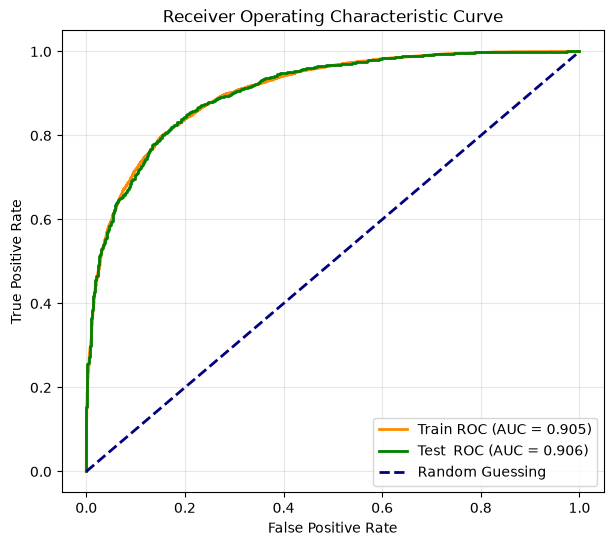

In [19]:
# ROC_AUC on training data
y_train_proba = model.predict_proba(X_train)[:,1]
fpr_train,tpr_train,_ = roc_curve(Y_train,y_train_proba)
roc_auc_train = auc(fpr_train,tpr_train)

# ROC_AUC on testing data
y_test_proba = model.predict_proba(X_test)[:,1]
fpr_test,tpr_test,_ = roc_curve(Y_test,y_test_proba)
roc_auc_test = auc(fpr_test,tpr_test)

print(f"Train ROC-AUC : {roc_auc_train:.4f}")
print(f"Test ROC-AUC : {roc_auc_test:.4f}")

# Plot ROC curves

plt.figure(figsize=(7, 6))
plt.plot(fpr_train, tpr_train, color='darkorange', lw=2, label=f'Train ROC (AUC = {roc_auc_train:.3f})')
plt.plot(fpr_test, tpr_test, color='green', lw=2, label=f'Test  ROC (AUC = {roc_auc_test:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic Curve')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

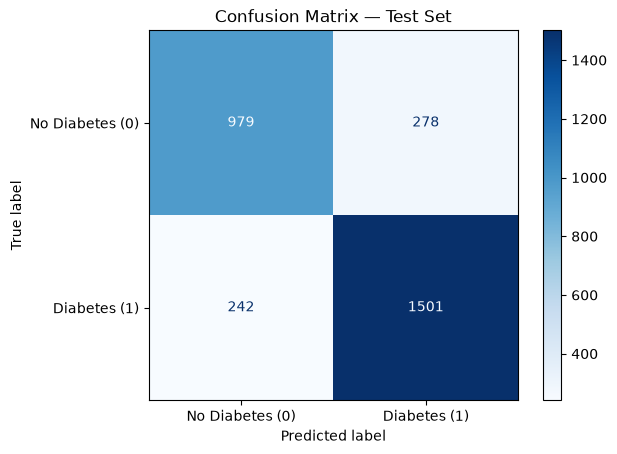

True Negatives (correctly healthy):  979
False Positives (false alarm):       278
False Negatives (missed diagnosis):  242
True Positives (correctly diabetic): 1501


In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(Y_test, model.predict(X_test))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Diabetes (0)", "Diabetes (1)"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Test Set")
plt.show()

# Breakdown
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives (correctly healthy):  {tn}")
print(f"False Positives (false alarm):       {fp}")
print(f"False Negatives (missed diagnosis):  {fn}")
print(f"True Positives (correctly diabetic): {tp}")

In [20]:
# Extract and interpret coefficients
coef = model.named_steps["clf"].coef_[0]
features = X.columns
coef_df = pd.DataFrame({"Feature": features, "Coefficient": coef})
coef_df = coef_df.sort_values("Coefficient", ascending=False).reset_index(drop=True)

# Calculate odds ratios (exponentiated coefficients) — easier to interpret
coef_df["Odds Ratio"] = np.exp(coef_df["Coefficient"])

print("=== MODEL COEFFICIENTS (sorted by impact) ===")
print(coef_df.to_string(index=False))

print("\n=== INTERPRETATION ===")
print("Positive coefficient  → higher values INCREASE diabetes risk")
print("Negative coefficient  → higher values DECREASE diabetes risk")
print("Odds Ratio > 1        → risk factor")
print("Odds Ratio < 1        → protective factor")

=== MODEL COEFFICIENTS (sorted by impact) ===
         Feature  Coefficient  Odds Ratio
             Age     1.509124    4.522766
         Glucose     1.135135    3.111594
   FamilyHistory     0.881194    2.413781
             BMI     0.715638    2.045491
GeneticRiskScore     0.649543    1.914665
         Smoking     0.602228    1.826183
   BloodPressure     0.497453    1.644527
         Alcohol     0.363287    1.438049
   SkinThickness     0.246370    1.279373
         Insulin     0.235412    1.265429
     Cholesterol     0.084654    1.088340
       HeartRate     0.076105    1.079075
          Gender     0.003512    1.003518
PhysicalActivity    -0.979809    0.375383

=== INTERPRETATION ===
Positive coefficient  → higher values INCREASE diabetes risk
Negative coefficient  → higher values DECREASE diabetes risk
Odds Ratio > 1        → risk factor
Odds Ratio < 1        → protective factor


In [ ]:
from sklearn.linear_model import LogisticRegressionCV

print("=== RIDGE (L2) vs LASSO (L1) CROSS-VALIDATION ===\n")

for penalty, label in [("l2", "L2 (Ridge)"), ("l1", "L1 (Lasso)")]:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegressionCV(
            Cs=[0.0001, 0.0005, 0.001, 0.01, 0.1, 1, 10, 50],
            cv=5,
            penalty=penalty,
            solver="liblinear",
            scoring="roc_auc",
            max_iter=2000,
            refit=True
        ))
    ])
    pipe.fit(X_train, Y_train)
    auc_score = roc_auc_score(Y_test, pipe.predict_proba(X_test)[:, 1])
    best_c = pipe.named_steps["clf"].C_[0]

    # Count near-zero coefficients (Lasso feature selection)
    coefs = pipe.named_steps["clf"].coef_[0]
    n_zero = (np.abs(coefs) < 1e-6).sum()

    print(f"{label}:")
    print(f"  Best C: {best_c}")
    print(f"  Test ROC-AUC: {auc_score:.4f}")
    print(f"  Features driven to ~0: {n_zero} / {len(coefs)}")
    print()

In [25]:
from sklearn.metrics import accuracy_score, roc_auc_score

# Accuracy scores
train_acc = accuracy_score(Y_train, Y_pred_train)
test_acc  = accuracy_score(Y_test, Y_pred_test)

# ROC-AUC scores
train_auc = roc_auc_score(Y_train, model.predict_proba(X_train)[:, 1])
test_auc  = roc_auc_score(Y_test, model.predict_proba(X_test)[:, 1])

print("=" * 50)
print("        MODEL PERFORMANCE SUMMARY")
print("=" * 50)
print(f"{'Metric':<22} {'Train':>10} {'Test':>10}")
print("-" * 50)
print(f"{'Accuracy':<22} {train_acc:>10.4f} {test_acc:>10.4f}")
print(f"{'ROC-AUC':<22} {train_auc:>10.4f} {test_auc:>10.4f}")
print("=" * 50)

        MODEL PERFORMANCE SUMMARY
Metric                      Train       Test
--------------------------------------------------
Accuracy                   0.8237     0.8267
ROC-AUC                    0.9051     0.9060


# Type 2 Diabetes Risk Predictor

A **Logistic Regression** model trained on 15,000 synthetic patient records to predict the likelihood of a Type 2 diabetes diagnosis.

## 📊 Model Performance

| Metric | Train | Test |
|---|---|---|
| Accuracy | 0.8237 | 0.8267 |
| ROC-AUC | 0.9051 | 0.9060 |

Train and test scores are nearly identical — **no overfitting**. ROC-AUC of 0.906 indicates strong discriminative ability.

## 🔍 Key Findings

The model's coefficients align with clinical understanding:

- **Age** (+1.51) — strongest risk factor, prevalence rises sharply after 45
- **Glucose** (+1.14) — most direct metabolic signal, closest to actual diagnostic tests
- **Physical Activity** (-0.98) — strongest protective factor
- **Family History** (+0.88) — hereditary predisposition captured
- **BMI** (+0.72) — obesity drives insulin resistance

This isn't a black box — the weights reflect known medical risk factors.

## 🚀 Run the App

```bash
pip install streamlit pandas scikit-learn
streamlit run streamlit_app.py
```

## ⚠️ Disclaimer

Demonstration model trained on **synthetic data**. Not for clinical use. Not a substitute for professional medical advice.